# Credit Risk Analytics with PD, LGD, EAD and ECL

This notebook is a beginner-friendly end-to-end credit risk project using Lending Club loan data.

We will:

- understand the dataset,
- define a historical default target,
- analyze default patterns,
- manually prepare features,
- train Logistic Regression as the only model,
- evaluate the model,
- explain PD, LGD, EAD and ECL,
- calculate illustrative ECL,
- create risk segments,
- save essential outputs.

Important note: this is an educational credit risk analytics project. It is not an IFRS 9 compliant production model.

## 1. Import Libraries and Set Up Folders

We import only the libraries needed for this project. The `outputs` folder stores charts, CSV files and metrics generated by the notebook.

In [1]:
import os
from pathlib import Path

os.environ.setdefault("MPLBACKEND", "Agg")
os.environ.setdefault("MPLCONFIGDIR", str(Path(".matplotlib_cache").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    brier_score_loss,
)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
DATA_PATH = Path("loan_data_2007_2014.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

## 2. Load and Understand the Data

We preserve the variable names `loan_data_backup` and `loan_data`.

`loan_data_backup` keeps the original imported data. `loan_data` is the working copy we can clean and transform.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. Place loan_data_2007_2014.csv in the project folder."
    )

loan_data_backup = pd.read_csv(DATA_PATH, low_memory=False)
loan_data = loan_data_backup.copy()

print("Dataset shape:", loan_data.shape)
print("Duplicate rows:", loan_data.duplicated().sum())
loan_data.head()

Dataset shape: (466285, 75)


Duplicate rows: 0


,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,B,B2,NaN,10+ years,RENT,24000.0,Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I need to upgra...,credit_card,Computer,860xx,AZ,27.65,0.0,Jan-85,1.0,NaN,NaN,3.0,0.0,13648,83.7,9.0,f,0.0,0.0,5861.071414,5831.78,5000.00,861.07,0.00,0.00,0.00,Jan-15,171.62,NaN,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,C,C4,Ryder,< 1 year,RENT,30000.0,Source Verified,Dec-11,Charged Off,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I plan to use t...,car,bike,309xx,GA,1.00,0.0,Apr-99,5.0,NaN,NaN,3.0,0.0,1687,9.4,4.0,f,0.0,0.0,1008.710000,1008.71,456.46,435.17,0.00,117.08,1.11,Apr-13,119.66,NaN,Sep-13,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,C,C5,NaN,10+ years,RENT,12252.0,Not Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,NaN,small_business,real estate business,606xx,IL,8.72,0.0,Nov-01,2.0,NaN,NaN,2.0,0.0,2956,98.5,10.0,f,0.0,0.0,3003.653644,3003.65,2400.00,603.65,0.00,0.00,0.00,Jun-14,649.91,NaN,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,C,C1,AIR RESOURCES BOARD,10+ years,RENT,49200.0,Source Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/21/11 > to pay for prop...,other,personel,917xx,CA,20.00,0.0,Feb-96,1.0,35.0,NaN,10.0,0.0,5598,21.0,37.0,f,0.0,0.0,12226.302210,12226.30,10000.00,2209.33,16.97,0.00,0.00,Jan-15,357.48,NaN,Jan-15,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,B,B5,University Medical Group,1 year,RENT,80000.0,Source Verified,Dec-11,Current,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/21/11 > I plan on combi...,other,Personal,972xx,OR,17.94,0.0,Jan-96,0.0,38.0,NaN,15.0,0.0,27783,53.9,38.0,f,766.9,766.9,3242.170000,3242.17,2233.10,1009.07,0.00,0.00,0.00,Jan-16,67.79,Feb-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print("Column names:")
print(loan_data.columns.tolist())

print("\nData types:")
display(loan_data.dtypes.to_frame("dtype"))

print("\nTop missing values:")
display(loan_data.isna().sum().sort_values(ascending=False).head(25).to_frame("missing_count"))

print("\nNumerical summary:")
display(loan_data.describe().T.head(25))

Column names:
['Unnamed: 0', 'id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_il_

,dtype
Unnamed: 0,int64
id,int64
member_id,int64
loan_amnt,int64
funded_amnt,int64
...,...
all_util,float64
total_rev_hi_lim,float64
inq_fi,float64
total_cu_tl,float64



Top missing values:


,missing_count
max_bal_bc,466285
open_rv_24m,466285
inq_fi,466285
open_rv_12m,466285
il_util,466285
mths_since_rcnt_il,466285
total_bal_il,466285
open_il_24m,466285
open_il_12m,466285
open_il_6m,466285



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,466285.0,2.331420e+05,1.346050e+05,0.00,1.165710e+05,2.331420e+05,3.497130e+05,4.662840e+05
id,466285.0,1.307973e+07,1.089371e+07,54734.00,3.639987e+06,1.010790e+07,2.073121e+07,3.809811e+07
member_id,466285.0,1.459766e+07,1.168237e+07,70473.00,4.379705e+06,1.194108e+07,2.300154e+07,4.086083e+07
loan_amnt,466285.0,1.431728e+04,8.286509e+03,500.00,8.000000e+03,1.200000e+04,2.000000e+04,3.500000e+04
funded_amnt,466285.0,1.429180e+04,8.274371e+03,500.00,8.000000e+03,1.200000e+04,2.000000e+04,3.500000e+04
funded_amnt_inv,466285.0,1.422233e+04,8.297638e+03,0.00,8.000000e+03,1.200000e+04,1.995000e+04,3.500000e+04
int_rate,466285.0,1.382924e+01,4.357587e+00,5.42,1.099000e+01,1.366000e+01,1.649000e+01,2.606000e+01
installment,466285.0,4.320612e+02,2.434855e+02,15.67,2.566900e+02,3.798900e+02,5.665800e+02,1.409990e+03
annual_inc,466281.0,7.327738e+04,5.496357e+04,1896.00,4.500000e+04,6.300000e+04,8.896000e+04,7.500000e+06
dti,466285.0,1.721876e+01,7.851121e+00,0.00,1.136000e+01,1.687000e+01,2.278000e+01,3.999000e+01


In [4]:
if "loan_status" not in loan_data.columns:
    raise KeyError("loan_status column is required to define the default target.")

loan_status_counts = loan_data["loan_status"].value_counts(dropna=False)
print("Loan status categories:")
display(loan_status_counts.to_frame("loan_count"))

Loan status categories:


,loan_count
loan_status,
Current,224226
Fully Paid,184739
Charged Off,42475
Late (31-120 days),6900
In Grace Period,3146
Does not meet the credit policy. Status:Fully Paid,1988
Late (16-30 days),1218
Default,832
Does not meet the credit policy. Status:Charged Off,761


### Practice Questions

1. Why do we keep a backup copy of the dataset?
2. Why should we inspect `loan_status` before defining the target?
3. Why should we avoid deleting all rows with missing values without understanding them?

## 3. Clean the Data and Define the Target

We create a binary target called `default_flag`.

- `1` means the loan had a default-related outcome.
- `0` means the loan was fully paid.
- Current or unresolved loans are excluded because their final outcome is not yet known.

This target is a historical outcome proxy. It is not automatically a calibrated 12-month IFRS 9 PD definition.

In [5]:
def map_loan_status(status):
    if pd.isna(status):
        return np.nan
    status = str(status).strip()
    if status == "Fully Paid":
        return 0
    if status in [
        "Charged Off",
        "Default",
        "Late (31-120 days)",
        "Does not meet the credit policy. Status:Charged Off",
    ]:
        return 1
    return np.nan

mapping_check = loan_data["loan_status"].value_counts(dropna=False).rename_axis("loan_status").reset_index(name="loan_count")
mapping_check["default_flag"] = mapping_check["loan_status"].map(map_loan_status)
mapping_check["mapping_decision"] = mapping_check["default_flag"].map({0: "fully_paid", 1: "default_related"}).fillna("excluded")
display(mapping_check)

loan_data["default_flag"] = loan_data["loan_status"].map(map_loan_status)
loan_data = loan_data.dropna(subset=["default_flag"]).copy()
loan_data["default_flag"] = loan_data["default_flag"].astype(int)

print("Rows after excluding unresolved outcomes:", len(loan_data))
print("Fully paid loans:", (loan_data["default_flag"] == 0).sum())
print("Default-related loans:", (loan_data["default_flag"] == 1).sum())
print("Historical default rate:", round(loan_data["default_flag"].mean(), 4))
display(loan_data["default_flag"].value_counts(normalize=False).to_frame("loan_count"))

,loan_status,loan_count,default_flag,mapping_decision
0,Current,224226,NaN,excluded
1,Fully Paid,184739,0.0,fully_paid
2,Charged Off,42475,1.0,default_related
3,Late (31-120 days),6900,1.0,default_related
4,In Grace Period,3146,NaN,excluded
5,Does not meet the credit policy. Status:Fully ...,1988,NaN,excluded
6,Late (16-30 days),1218,NaN,excluded
7,Default,832,1.0,default_related
8,Does not meet the credit policy. Status:Charge...,761,1.0,default_related


Rows after excluding unresolved outcomes: 235707
Fully paid loans: 184739
Default-related loans: 50968
Historical default rate: 0.2162


,loan_count
default_flag,
0,184739
1,50968


## 4. Exploratory Data Analysis

EDA helps a credit risk analyst understand which borrower or loan groups have higher observed default rates.

The charts below are descriptive. They show associations in historical data, not causation.

In [6]:
def clean_percent_column(series):
    return pd.to_numeric(series.astype(str).str.replace("%", "", regex=False).str.strip(), errors="coerce")

if "int_rate" in loan_data.columns:
    loan_data["int_rate_clean"] = clean_percent_column(loan_data["int_rate"])

eda_summary_rows = []

def default_rate_table(df, group_col):
    table = df.groupby(group_col, dropna=False).agg(
        loan_count=("default_flag", "size"),
        default_count=("default_flag", "sum"),
        default_rate=("default_flag", "mean"),
    ).reset_index()
    return table.sort_values("default_rate", ascending=False)

if "int_rate_clean" in loan_data.columns:
    loan_data["int_rate_band"] = pd.cut(loan_data["int_rate_clean"], bins=[0, 8, 12, 16, 20, 100], include_lowest=True)
if "dti" in loan_data.columns:
    loan_data["dti_band"] = pd.cut(pd.to_numeric(loan_data["dti"], errors="coerce"), bins=[0, 10, 20, 30, 40, 100], include_lowest=True)
if "annual_inc" in loan_data.columns:
    loan_data["income_band"] = pd.cut(pd.to_numeric(loan_data["annual_inc"], errors="coerce"), bins=[0, 30000, 60000, 100000, 150000, np.inf], include_lowest=True)
if "loan_amnt" in loan_data.columns:
    loan_data["loan_amount_band"] = pd.cut(pd.to_numeric(loan_data["loan_amnt"], errors="coerce"), bins=[0, 5000, 10000, 15000, 25000, 40000], include_lowest=True)

summary = pd.DataFrame({
    "metric": ["total_completed_loans", "default_related_loans", "historical_default_rate"],
    "value": [len(loan_data), int(loan_data["default_flag"].sum()), loan_data["default_flag"].mean()],
})
display(summary)
summary.to_csv(OUTPUT_DIR / "eda_summary.csv", index=False)

,metric,value
0,total_completed_loans,235707.000000
1,default_related_loans,50968.000000
2,historical_default_rate,0.216235


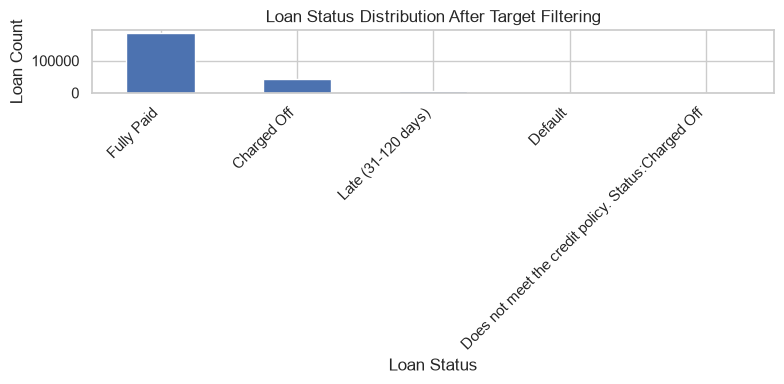

In [7]:
plt.figure(figsize=(8, 4))
loan_data["loan_status"].value_counts().plot(kind="bar")
plt.title("Loan Status Distribution After Target Filtering")
plt.xlabel("Loan Status")
plt.ylabel("Loan Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "loan_status_distribution.png", dpi=150)
plt.show()

,grade,loan_count,default_count,default_rate
6,G,1843,924,0.501356
5,F,7119,3192,0.448378
4,E,17533,6964,0.397194
3,D,37937,11848,0.312307
2,C,60202,14384,0.238929
1,B,71721,10759,0.150012
0,A,39352,2897,0.073618


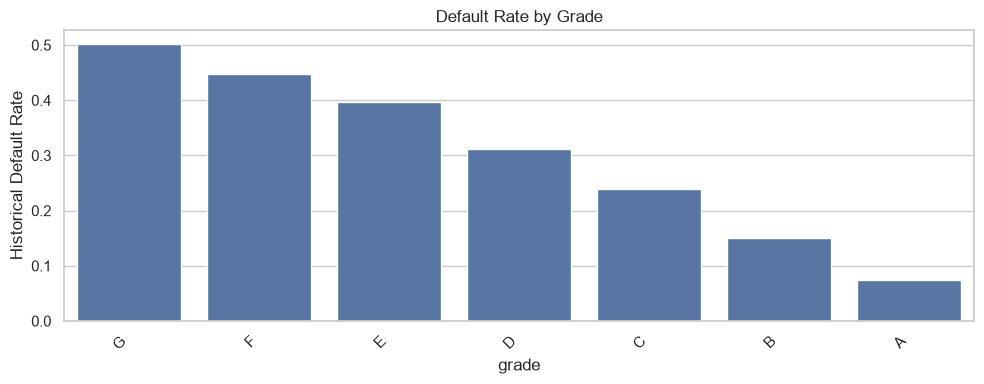

,int_rate_band,loan_count,default_count,default_rate
4,"(20.0, 100.0]",20737,8782,0.423494
3,"(16.0, 20.0]",47125,14973,0.317729
2,"(12.0, 16.0]",86877,18534,0.213336
1,"(8.0, 12.0]",51931,6836,0.131636
0,"(-0.001, 8.0]",29037,1843,0.063471


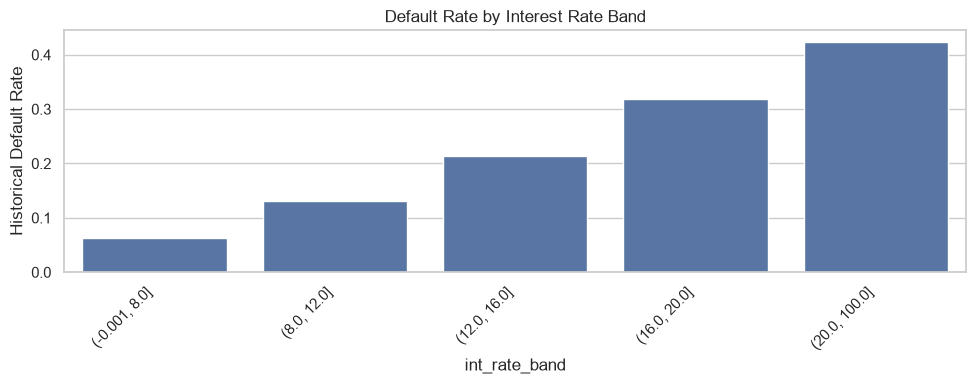

,dti_band,loan_count,default_count,default_rate
3,"(30.0, 40.0]",10712,3698,0.345220
2,"(20.0, 30.0]",65980,17679,0.267945
1,"(10.0, 20.0]",106988,21444,0.200434
0,"(-0.001, 10.0]",52027,8147,0.156592


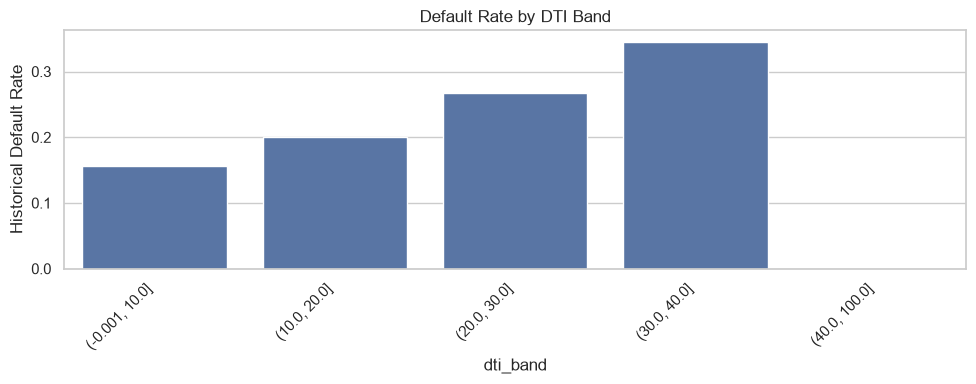

,income_band,loan_count,default_count,default_rate
0,"(-0.001, 30000.0]",18546,5195,0.280114
1,"(30000.0, 60000.0]",97687,23849,0.244137
2,"(60000.0, 100000.0]",82392,15987,0.194036
3,"(100000.0, 150000.0]",27575,4443,0.161124
4,"(150000.0, inf]",9507,1494,0.157147


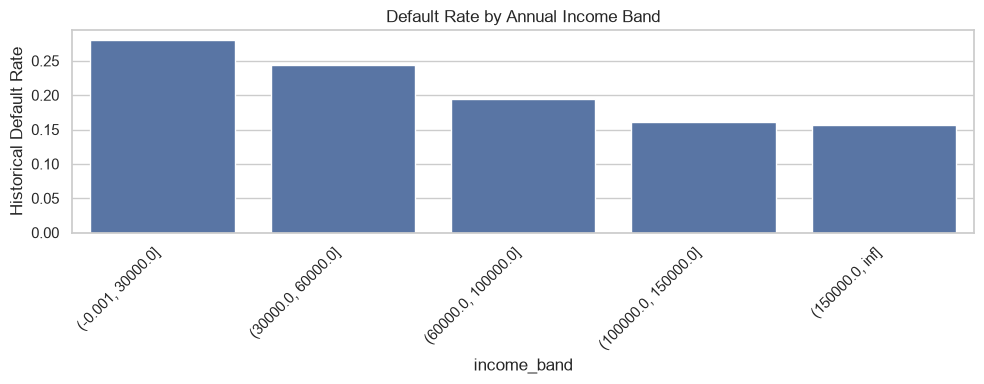

,purpose,loan_count,default_count,default_rate
11,small_business,4677,1513,0.323498
3,educational,357,88,0.246499
8,moving,1861,457,0.245567
9,other,13332,3269,0.245200
7,medical,2670,616,0.230712
2,debt_consolidation,137510,31069,0.225940
10,renewable_energy,254,54,0.212598
5,house,1500,318,0.212000
12,vacation,1443,293,0.203049
1,credit_card,47150,8981,0.190477


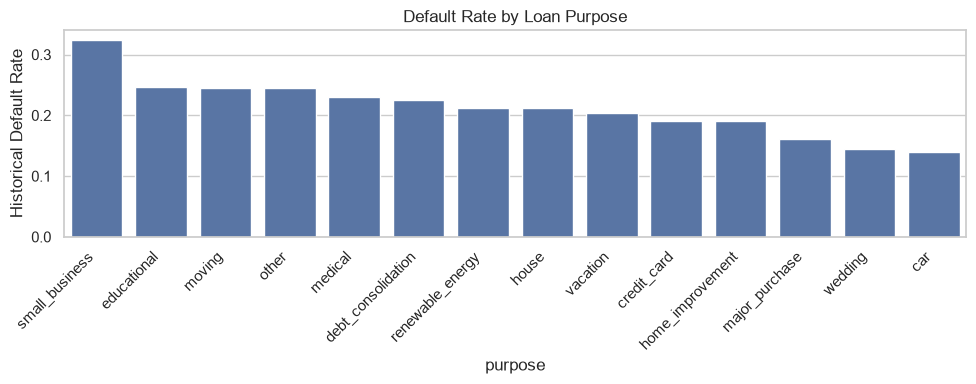

,loan_amount_band,loan_count,default_count,default_rate
4,"(25000.0, 40000.0]",20857,5874,0.281632
3,"(15000.0, 25000.0]",58690,14424,0.245766
2,"(10000.0, 15000.0]",52455,11030,0.210275
1,"(5000.0, 10000.0]",70710,13556,0.191713
0,"(-0.001, 5000.0]",32995,6084,0.184392


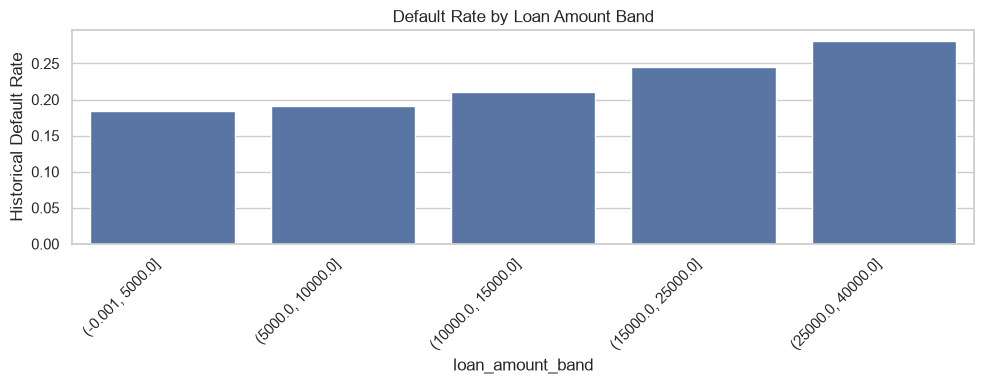

In [8]:
plot_columns = [
    ("grade", "Default Rate by Grade"),
    ("int_rate_band", "Default Rate by Interest Rate Band"),
    ("dti_band", "Default Rate by DTI Band"),
    ("income_band", "Default Rate by Annual Income Band"),
    ("purpose", "Default Rate by Loan Purpose"),
    ("loan_amount_band", "Default Rate by Loan Amount Band"),
]

eda_tables = {}
for column, title in plot_columns:
    if column in loan_data.columns:
        table = default_rate_table(loan_data, column)
        eda_tables[column] = table
        display(table.head(15))
        plt.figure(figsize=(10, 4))
        sns.barplot(data=table.head(15), x=column, y="default_rate")
        plt.title(title)
        plt.xlabel(column)
        plt.ylabel("Historical Default Rate")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        safe_name = column.replace("_", "-")
        plt.savefig(OUTPUT_DIR / f"{safe_name}_default_rate.png", dpi=150)
        plt.show()

### Practice Questions

1. Why should default-rate charts include loan counts?
2. Why does a high default rate in a tiny group need caution?
3. Why can interest rate and grade be tricky to interpret in credit data?

## 5. Prepare Features Manually

We use only information that could reasonably be known before or at loan origination.

We exclude `loan_status`, `default_flag`, payments, recoveries, collection fields and other future performance fields.

The preprocessing is manual:

1. Select features and target.
2. Split into train and test.
3. Fill missing values using training data only.
4. Encode categories with `pd.get_dummies()`.
5. Align train and test columns.
6. Scale numeric columns using parameters learned from training data only.

In [9]:
candidate_features = [
    "loan_amnt",
    "annual_inc",
    "dti",
    "int_rate_clean",
    "grade",
    "purpose",
    "home_ownership",
    "verification_status",
]

available_features = [col for col in candidate_features if col in loan_data.columns]
print("Available model features:", available_features)

X = loan_data[available_features].copy()
y = loan_data["default_flag"].copy()

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [col for col in X.columns if col not in numeric_features]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("X shape:", X.shape)
print("y shape:", y.shape)

Available model features: ['loan_amnt', 'annual_inc', 'dti', 'int_rate_clean', 'grade', 'purpose', 'home_ownership', 'verification_status']
Numeric features: ['loan_amnt', 'annual_inc', 'dti', 'int_rate_clean']
Categorical features: ['grade', 'purpose', 'home_ownership', 'verification_status']
X shape: (235707, 8)
y shape: (235707,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y,
)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print("Training default rate:", round(y_train.mean(), 4))
print("Test default rate:", round(y_test.mean(), 4))

Training rows: 188565
Test rows: 47142
Training default rate: 0.2162
Test default rate: 0.2162


In [11]:
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

numeric_medians = X_train_clean[numeric_features].median()
X_train_clean[numeric_features] = X_train_clean[numeric_features].fillna(numeric_medians)
X_test_clean[numeric_features] = X_test_clean[numeric_features].fillna(numeric_medians)

categorical_modes = {}
for col in categorical_features:
    mode_value = X_train_clean[col].mode(dropna=True)
    fill_value = mode_value.iloc[0] if not mode_value.empty else "Missing"
    categorical_modes[col] = fill_value
    X_train_clean[col] = X_train_clean[col].fillna(fill_value).astype(str)
    X_test_clean[col] = X_test_clean[col].fillna(fill_value).astype(str)

X_train_encoded = pd.get_dummies(X_train_clean, columns=categorical_features, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_clean, columns=categorical_features, drop_first=True)

X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join="left", axis=1, fill_value=0)

scaler = StandardScaler()
X_train_encoded[numeric_features] = scaler.fit_transform(X_train_encoded[numeric_features])
X_test_encoded[numeric_features] = scaler.transform(X_test_encoded[numeric_features])

print("Final training shape:", X_train_encoded.shape)
print("Final test shape:", X_test_encoded.shape)
print("Any missing values in train:", int(X_train_encoded.isna().sum().sum()))
print("Any missing values in test:", int(X_test_encoded.isna().sum().sum()))

Final training shape: (188565, 29)
Final test shape: (47142, 29)
Any missing values in train: 0
Any missing values in test: 0


## 6. Train Logistic Regression

Logistic Regression estimates the probability of a binary outcome. Here the outcome is `default_flag`.

- `fit()` means the model learns coefficients from training data.
- `predict()` returns class labels using a default threshold of 0.5.
- `predict_proba()` returns probabilities. The probability for class `1` is our predicted PD proxy.

In [12]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
y_prob = model.predict_proba(X_test_encoded)[:, 1]

print("First 10 predicted default probabilities:")
print(y_prob[:10])

First 10 predicted default probabilities:
[0.28170256 0.09548356 0.16198671 0.1383801  0.20749309 0.22413221
 0.09508986 0.12469298 0.28881565 0.33241941]


## 7. Evaluate the Model

Accuracy can be misleading when default cases are less common than non-default cases. A model can look accurate while missing many defaults.

We calculate several metrics and use ROC-AUC and KS to evaluate score ranking quality.

In [13]:
def calculate_ks_statistic(y_true, y_scores):
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    ks_values = np.abs(tpr - fpr)
    best_index = np.argmax(ks_values)
    return ks_values[best_index], thresholds[best_index]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)
ks_stat, ks_threshold = calculate_ks_statistic(y_test, y_prob)
brier = brier_score_loss(y_test, y_prob)

model_metrics = pd.DataFrame({
    "metric": ["accuracy", "precision", "recall", "f1_score", "roc_auc", "ks_statistic", "ks_threshold", "brier_score"],
    "value": [accuracy, precision, recall, f1, roc_auc, ks_stat, ks_threshold, brier],
})

display(model_metrics)
print(classification_report(y_test, y_pred, zero_division=0))
model_metrics.to_csv(OUTPUT_DIR / "model_metrics.csv", index=False)

,metric,value
0,accuracy,0.786390
1,precision,0.557728
2,recall,0.058760
3,f1_score,0.106319
4,roc_auc,0.697863
5,ks_statistic,0.288854
6,ks_threshold,0.221036
7,brier_score,0.154986


              precision    recall  f1-score   support

           0       0.79      0.99      0.88     36948
           1       0.56      0.06      0.11     10194

    accuracy                           0.79     47142
   macro avg       0.67      0.52      0.49     47142
weighted avg       0.74      0.79      0.71     47142



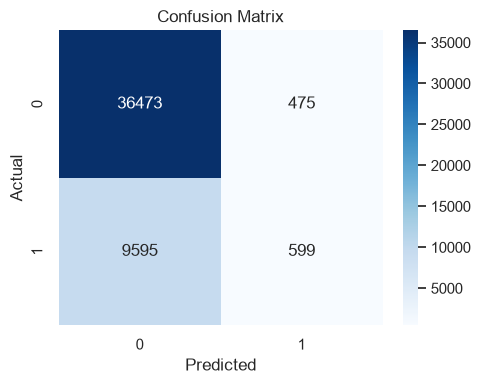

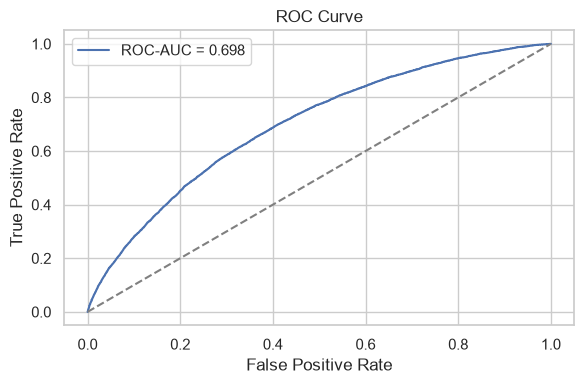

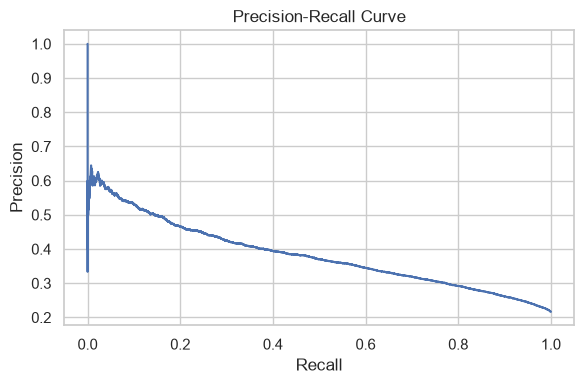

In [14]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curve.png", dpi=150)
plt.show()

precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
plt.figure(figsize=(6, 4))
plt.plot(recall_curve, precision_curve)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "precision_recall_curve.png", dpi=150)
plt.show()

In [15]:
coefficients = pd.DataFrame({
    "feature": X_train_encoded.columns,
    "coefficient": model.coef_[0],
})
coefficients["odds_ratio"] = np.exp(coefficients["coefficient"])
coefficients = coefficients.sort_values("coefficient", ascending=False)

display(coefficients.head(15))
display(coefficients.tail(15))

,feature,coefficient,odds_ratio
9,grade_G,1.370508,3.937352
8,grade_F,1.222950,3.397196
7,grade_E,1.202358,3.327955
6,grade_D,1.015687,2.761259
5,grade_C,0.833252,2.300789
20,purpose_small_business,0.523219,1.687451
4,grade_B,0.488853,1.630445
12,purpose_educational,0.417768,1.518569
3,int_rate_clean,0.234211,1.263911
24,home_ownership_OTHER,0.230904,1.259739


,feature,coefficient,odds_ratio
19,purpose_renewable_energy,0.125072,1.133230
13,purpose_home_improvement,0.095038,1.099701
25,home_ownership_OWN,0.092849,1.097296
17,purpose_moving,0.082053,1.085513
18,purpose_other,0.081647,1.085073
16,purpose_medical,0.057634,1.059327
28,verification_status_Verified,0.032353,1.032882
23,home_ownership_NONE,0.018017,1.018181
14,purpose_house,-0.021362,0.978865
11,purpose_debt_consolidation,-0.021970,0.978270


### Practice Questions

1. What does a predicted probability of `0.20` mean?
2. Why is recall important in default prediction?
3. Why should we avoid saying a coefficient proves causation?

## 8. PD, LGD, EAD and ECL

### Probability of Default (PD)

PD is the estimated probability that a borrower defaults over a defined time horizon.

In this project, PD is the Logistic Regression predicted probability:

`PD = model.predict_proba(X_test)[:, 1]`

This is a historical default probability proxy based on our target definition. It is not automatically a calibrated 12-month IFRS 9 PD.

### Loss Given Default (LGD)

LGD is the proportion of exposure lost if default occurs.

Formula:

`LGD = (EAD - Net Recovery) / EAD`

Example: if EAD is Rs. 100,000 and net recovery is Rs. 40,000, LGD is 60%.

Actual LGD modelling may need recovery timing, collateral, collection costs and discounting. In this notebook, we use an assumed LGD only for education.

### Exposure at Default (EAD)

EAD is the outstanding exposure when default occurs.

The original loan amount is not necessarily equal to EAD because some principal may already be repaid. Here we use `loan_amnt` as a clearly labelled exposure proxy.

### Expected Credit Loss (ECL)

Formula:

`ECL = PD x LGD x EAD`

Example: PD = 5%, LGD = 60%, EAD = Rs. 100,000.

`ECL = 0.05 x 0.60 x 100000 = Rs. 3,000`

PD and LGD must be decimals in the formula, not 5 and 60.

In [16]:
example_pd = 0.05
example_lgd = 0.60
example_ead = 100000
example_ecl = example_pd * example_lgd * example_ead
print("Example ECL:", example_ecl)

Example ECL: 3000.0


## 9. Calculate Illustrative ECL

We use actual predicted PD values from the model.

For EAD, we use `loan_amnt` as an exposure proxy because this simple project does not build a validated EAD model.

For LGD, we use a hypothetical assumption of 60% for education. This is not an actual portfolio LGD estimate.

In [17]:
ASSUMED_LGD = 0.60

results = X_test.copy()
results["actual_default_flag"] = y_test.values
results["predicted_pd"] = y_prob
results["assumed_lgd"] = ASSUMED_LGD

if "loan_amnt" in results.columns:
    results["ead_proxy"] = pd.to_numeric(results["loan_amnt"], errors="coerce").fillna(pd.to_numeric(X_train["loan_amnt"], errors="coerce").median())
else:
    results["ead_proxy"] = 0

results["illustrative_ecl"] = results["predicted_pd"] * results["assumed_lgd"] * results["ead_proxy"]

print("Total illustrative ECL:", round(results["illustrative_ecl"].sum(), 2))
print("Average illustrative ECL:", round(results["illustrative_ecl"].mean(), 2))

display(results[["actual_default_flag", "predicted_pd", "assumed_lgd", "ead_proxy", "illustrative_ecl"]].head())
results[["actual_default_flag", "predicted_pd", "assumed_lgd", "ead_proxy", "illustrative_ecl"]].to_csv(OUTPUT_DIR / "ecl_analysis.csv", index=False)

Total illustrative ECL: 89425081.83
Average illustrative ECL: 1896.93


,actual_default_flag,predicted_pd,assumed_lgd,ead_proxy,illustrative_ecl
187787,0,0.281703,0.6,9700,1639.508873
134798,0,0.095484,0.6,10000,572.901338
355300,0,0.161987,0.6,14000,1360.688405
411866,0,0.138380,0.6,10100,838.583421
444080,1,0.207493,0.6,35000,4357.354829


## 10. Risk Segmentation

We create simple illustrative risk bands from predicted PD.

- Low Risk: PD below 5%.
- Medium Risk: PD from 5% to below 15%.
- High Risk: PD of 15% or above.

These thresholds are examples for learning. They are not universal lending standards.

In [18]:
def assign_risk_segment(pd_value):
    if pd_value < 0.05:
        return "Low Risk"
    if pd_value < 0.15:
        return "Medium Risk"
    return "High Risk"

results["risk_segment"] = results["predicted_pd"].apply(assign_risk_segment)

risk_segment_summary = results.groupby("risk_segment").agg(
    loan_count=("actual_default_flag", "size"),
    average_predicted_pd=("predicted_pd", "mean"),
    observed_default_rate=("actual_default_flag", "mean"),
    total_exposure_proxy=("ead_proxy", "sum"),
    total_illustrative_ecl=("illustrative_ecl", "sum"),
).reset_index()

display(risk_segment_summary)
risk_segment_summary.to_csv(OUTPUT_DIR / "risk_segment_summary.csv", index=False)

,risk_segment,loan_count,average_predicted_pd,observed_default_rate,total_exposure_proxy,total_illustrative_ecl
0,High Risk,30888,0.279456,0.278684,441630375,7.817854e+07
1,Low Risk,1279,0.038888,0.035184,16064675,3.610747e+05
2,Medium Risk,14975,0.101748,0.102905,178317500,1.088547e+07


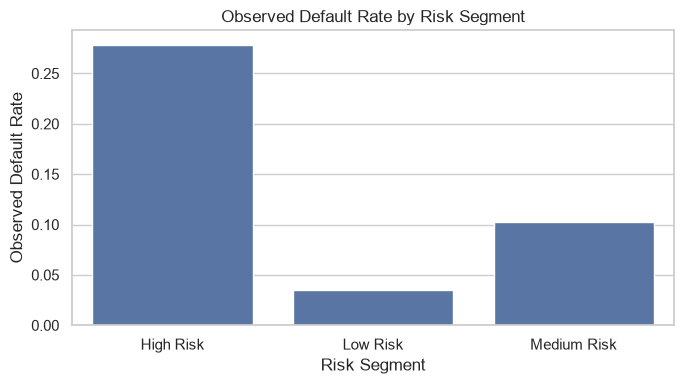

In [19]:
test_predictions = results[["actual_default_flag", "predicted_pd", "risk_segment", "ead_proxy", "illustrative_ecl"]].copy()
test_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

plt.figure(figsize=(7, 4))
sns.barplot(data=risk_segment_summary, x="risk_segment", y="observed_default_rate")
plt.title("Observed Default Rate by Risk Segment")
plt.xlabel("Risk Segment")
plt.ylabel("Observed Default Rate")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "risk_segment_default_rate.png", dpi=150)
plt.show()

## 11. Business Insights

This section calculates simple, explainable portfolio insights that a credit risk analyst can discuss in an interview.

In [20]:
print("Overall historical default rate:", round(loan_data["default_flag"].mean(), 4))

if "grade" in eda_tables:
    print("Default rate by grade:")
    display(eda_tables["grade"])

if "purpose" in eda_tables:
    print("Default rate by purpose:")
    display(eda_tables["purpose"].head(10))

if "dti_band" in eda_tables:
    print("Default rate by DTI category:")
    display(eda_tables["dti_band"])

print("Risk segment summary:")
display(risk_segment_summary)

Overall historical default rate: 0.2162
Default rate by grade:


,grade,loan_count,default_count,default_rate
6,G,1843,924,0.501356
5,F,7119,3192,0.448378
4,E,17533,6964,0.397194
3,D,37937,11848,0.312307
2,C,60202,14384,0.238929
1,B,71721,10759,0.150012
0,A,39352,2897,0.073618


Default rate by purpose:


,purpose,loan_count,default_count,default_rate
11,small_business,4677,1513,0.323498
3,educational,357,88,0.246499
8,moving,1861,457,0.245567
9,other,13332,3269,0.245200
7,medical,2670,616,0.230712
2,debt_consolidation,137510,31069,0.225940
10,renewable_energy,254,54,0.212598
5,house,1500,318,0.212000
12,vacation,1443,293,0.203049
1,credit_card,47150,8981,0.190477


Default rate by DTI category:


,dti_band,loan_count,default_count,default_rate
3,"(30.0, 40.0]",10712,3698,0.345220
2,"(20.0, 30.0]",65980,17679,0.267945
1,"(10.0, 20.0]",106988,21444,0.200434
0,"(-0.001, 10.0]",52027,8147,0.156592


Risk segment summary:


,risk_segment,loan_count,average_predicted_pd,observed_default_rate,total_exposure_proxy,total_illustrative_ecl
0,High Risk,30888,0.279456,0.278684,441630375,7.817854e+07
1,Low Risk,1279,0.038888,0.035184,16064675,3.610747e+05
2,Medium Risk,14975,0.101748,0.102905,178317500,1.088547e+07


### Supported Interpretation

- If a segment has higher observed default rates, it may deserve closer monitoring.
- Higher predicted PD segments also have higher illustrative ECL because ECL increases when PD increases.
- Grade and interest rate can be useful, but they may already include prior underwriting decisions.
- These findings show association in historical data, not causation.

### Final Practice Questions

1. What is the difference between PD and ECL?
2. Why is assumed LGD clearly labelled as hypothetical?
3. Why is `loan_amnt` only an EAD proxy in this project?
4. Which metric would you explain first in an interview, and why?

## 12. Files Saved

The notebook saves these essential outputs:

- `outputs/eda_summary.csv`
- `outputs/model_metrics.csv`
- `outputs/test_predictions.csv`
- `outputs/ecl_analysis.csv`
- `outputs/risk_segment_summary.csv`
- important PNG charts

In [21]:
print("Saved output files:")
for path in sorted(OUTPUT_DIR.glob("*")):
    print(path)

Saved output files:
outputs\confusion_matrix.png
outputs\dti-band_default_rate.png
outputs\ecl_analysis.csv
outputs\eda_summary.csv
outputs\grade_default_rate.png
outputs\income-band_default_rate.png
outputs\int-rate-band_default_rate.png
outputs\loan-amount-band_default_rate.png
outputs\loan_status_distribution.png
outputs\model_metrics.csv
outputs\precision_recall_curve.png
outputs\purpose_default_rate.png
outputs\risk_segment_default_rate.png
outputs\risk_segment_summary.csv
outputs\roc_curve.png
outputs\test_predictions.csv
